# 1_DataProcessing
In this notebook, we first use R to read in and explore the data from Brazil. The goal is to decide on the what parts of the data to use, and to format everything for easy reading into Python (for the creation of Darts TS objects). Part of this is also deciding on the training-validation-testing regimen to use.

There are three steps to this process:
1. Compute state-level dengue case data (provided values are at the municipality-level and need to be aggregated).
2. Compute state-level static covariates (we can use the proportion of each state living in each climate zone / biome).
3. Compute state-level meteorological values (municipality values provided but we can aggregate to state-level through population weighting).

In [1]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Reading Input

In [2]:
base_dir = getwd()
raw_data_dir = file.path(base_dir, "data_sprint_2025")
api_data_dir = file.path(base_dir, "API Downloaded")
other_data_dir = file.path(base_dir, "Other Data")
output_dir = file.path(base_dir, "ModelInput_Round2")

In [3]:
dengue_df = read_csv(file.path(raw_data_dir, "dengue.csv.gz")) #Dengue data
geo_df = read_csv(file.path(raw_data_dir, "map_regional_health.csv")) #Information on geocodes and admin hierarchy
pop_df = read_csv(file.path(raw_data_dir, "datasus_population_2001_2024.csv.gz")) #Population data
environ_df = read_csv(file.path(raw_data_dir, "environ_vars.csv.gz")) #Environmental variables (used for statis covariates). 
climate_df = read_csv(file.path(raw_data_dir, "climate.csv.gz")) #Municipality-level climate covariates
api_dl_clim_df = read_csv(file.path(api_data_dir, "climate_2025.csv")) #Municipality-level API-downloaded climate data (dfiff format from climate_df)

covid_index_df = read_csv(file.path(other_data_dir, "OxCGRT_compact_subnational_v1.csv"))

sst_df = read_csv(file.path(raw_data_dir, "ocean_climate_oscillations_update_2025.csv.gz")) %>% rename(Date = date) #Unlike dengue and climate, updated sst data "overwrites" the previous version (i.e. this file contains all the old data as well)

Rows: 4471809 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): uf
dbl  (5): epiweek, geocode, casos, macroregional_geocode, regional_geocode
lgl  (6): train_1, target_1, train_2, target_2, train_3, target_3
date (1): date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 5570 Columns: 11
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (6): macroregion_name, uf, uf_name, macroregional_name, regional_name, g...
dbl (5): macroregion_code, uf_code, macroregional_geocode, regional_geocode,...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 133680 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","


In [4]:
#Here we read in some updated data in preparation for the second round of the dengue forecasting competition
climate_df_updated = read_csv(file.path(raw_data_dir, "climate_updated_2025.csv.gz"))
dengue_df_updated = read_csv(file.path(raw_data_dir, "dengue_updated_2025.csv.gz"))

Rows: 139175 Columns: 17
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (16): epiweek, geocode, temp_min, temp_med, temp_max, precip_min, preci...
date  (1): date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 139250 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): uf
dbl  (5): epiweek, casos, geocode, macroregional_geocode, regional_geocode
date (1): date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Data Update Check

In [5]:
orig_dengue = dengue_df
new_dengue = dengue_df_updated
vis_uf = "AC"
orig_dengue = orig_dengue %>% filter(epiweek > 202500, uf == vis_uf) %>% mutate(Type = "Original") %>% select(-c(train_1, target_1, train_2, target_2, train_3, target_3)) %>% arrange(date, geocode)
new_dengue = new_dengue %>% filter(epiweek > 202500, uf == vis_uf) %>% mutate(Type = "Updated")%>% arrange(date, geocode)

update_check_df = rbind(orig_dengue, new_dengue)

In [6]:
orig_dengue

date,epiweek,geocode,casos,uf,macroregional_geocode,regional_geocode,Type
<date>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<chr>
2024-12-29,202501,1200013,0,AC,1201,12002,Original
2024-12-29,202501,1200054,0,AC,1201,12001,Original
2024-12-29,202501,1200104,2,AC,1201,12001,Original
2024-12-29,202501,1200138,0,AC,1201,12002,Original
2024-12-29,202501,1200179,1,AC,1201,12002,Original
2024-12-29,202501,1200203,238,AC,1201,12003,Original
2024-12-29,202501,1200252,1,AC,1201,12001,Original
2024-12-29,202501,1200302,20,AC,1201,12003,Original
2024-12-29,202501,1200328,0,AC,1201,12002,Original


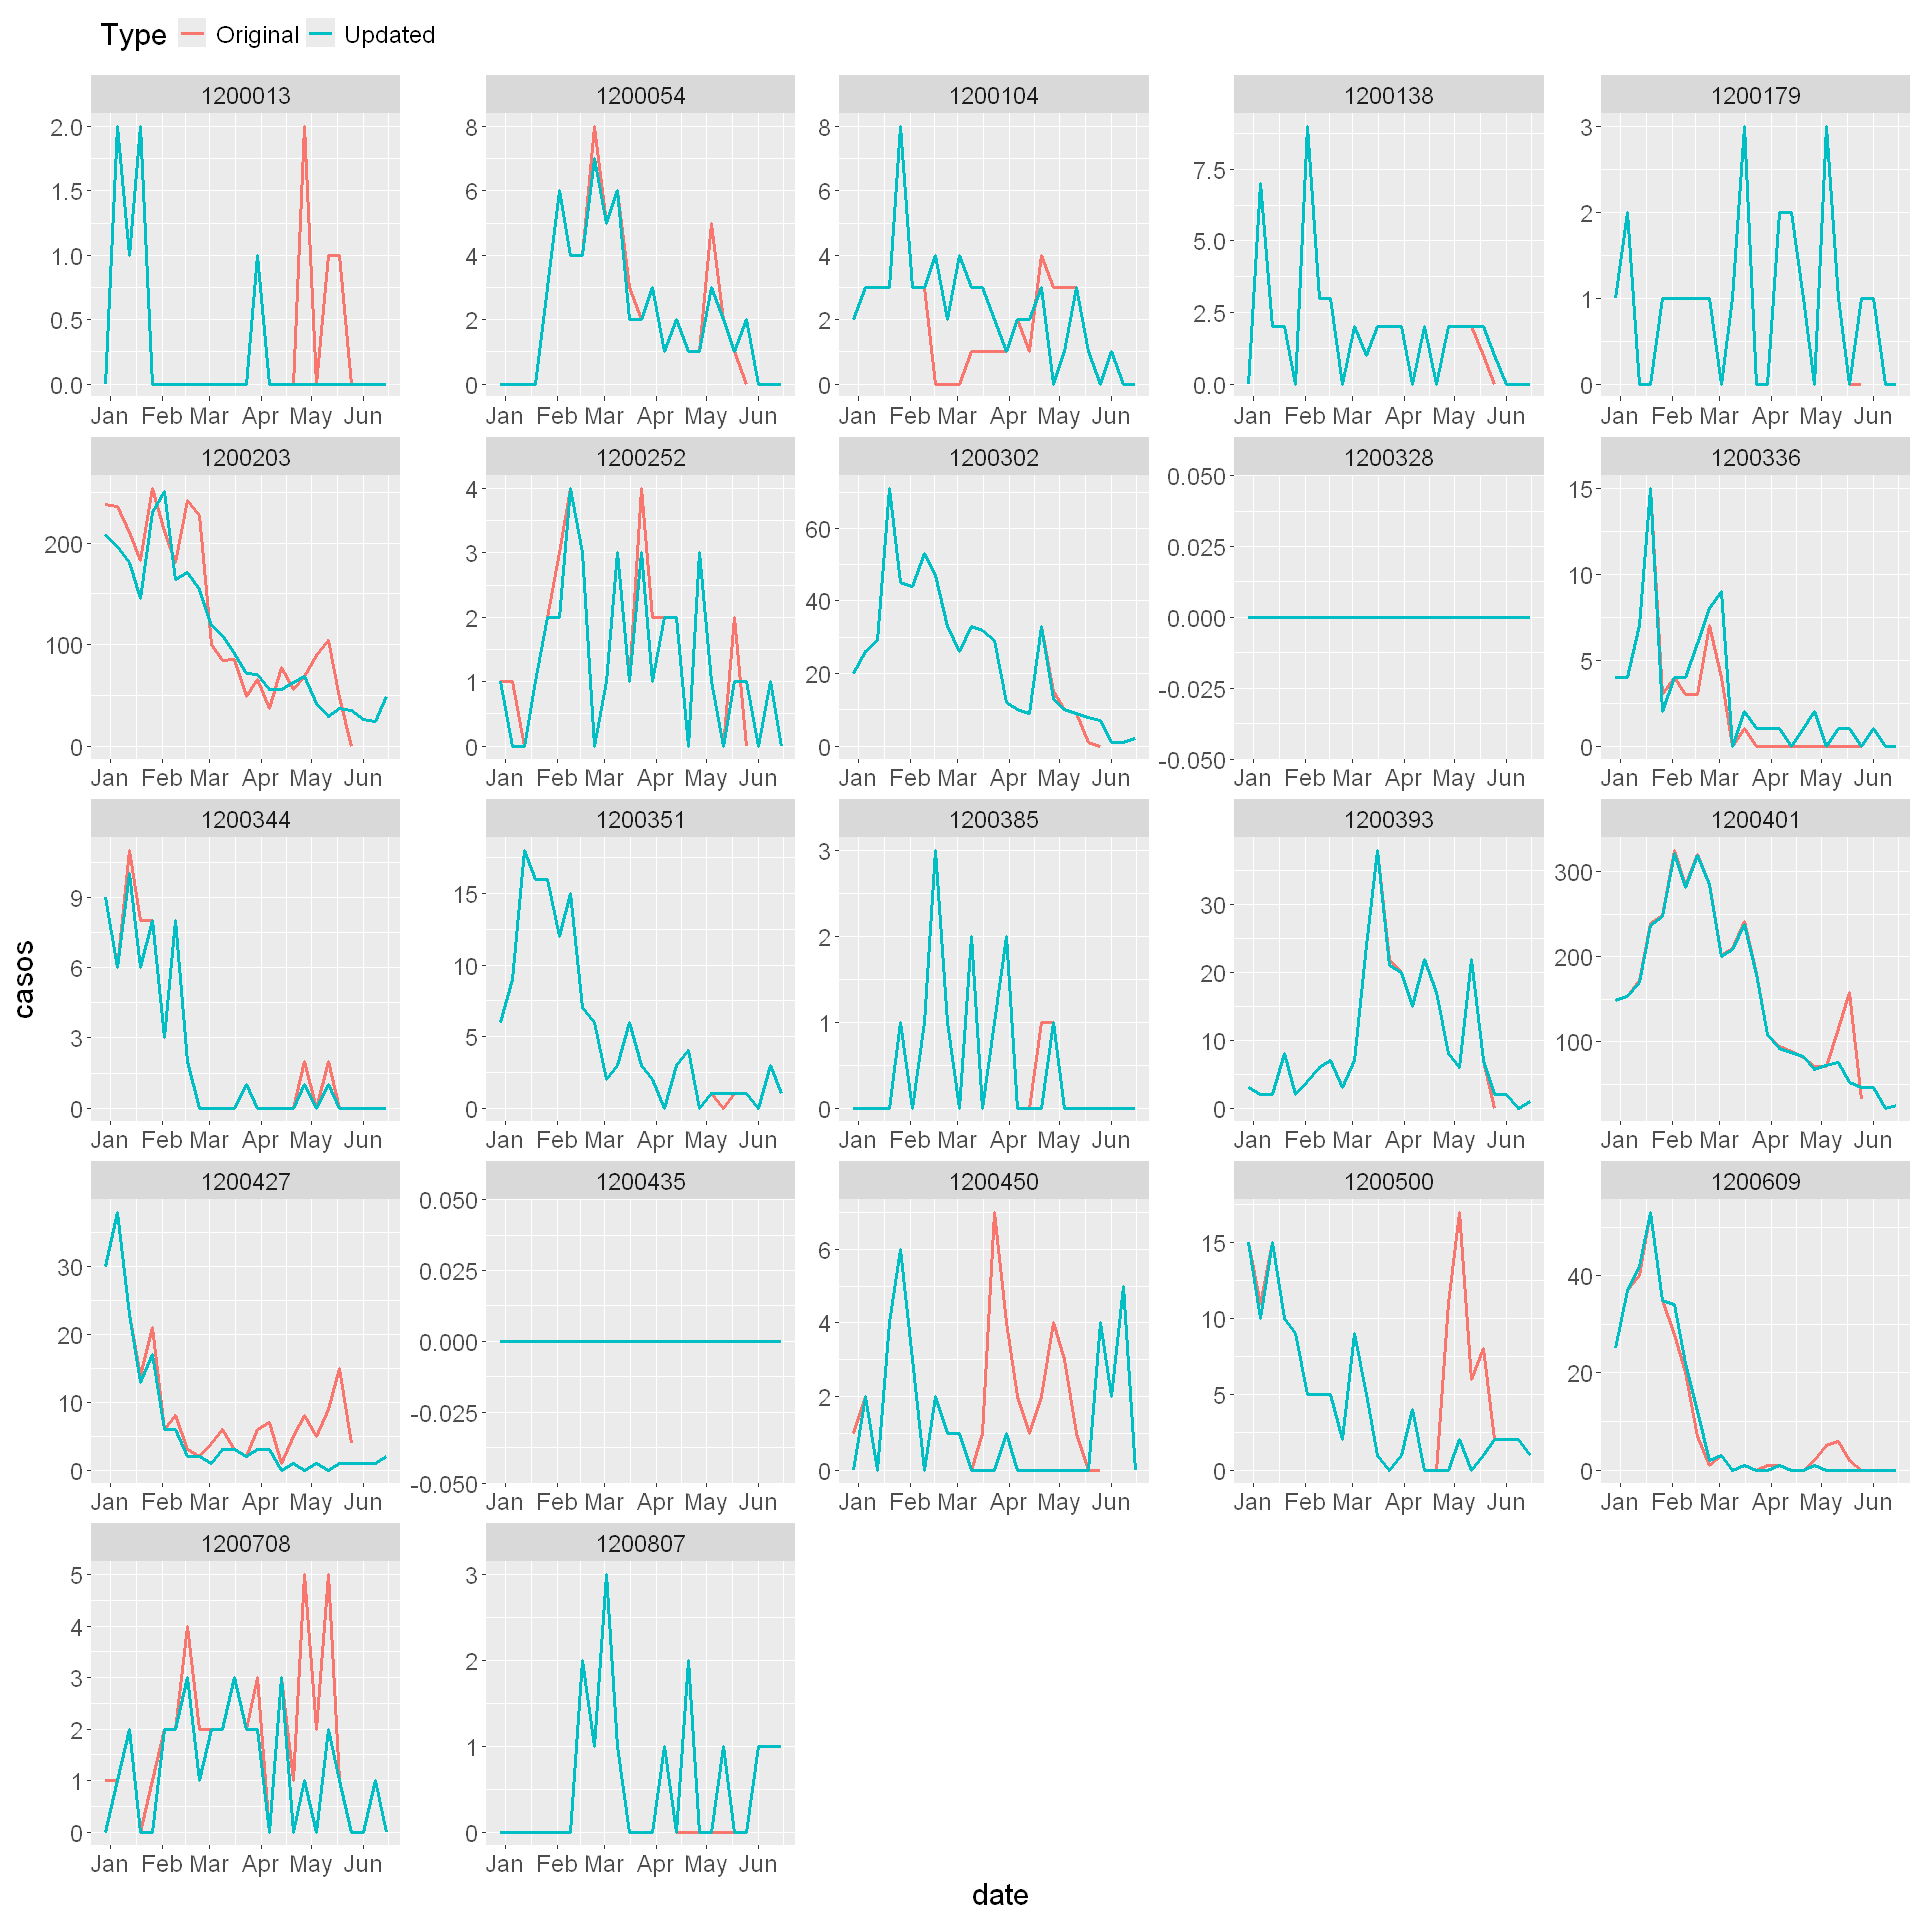

In [7]:
options(repr.plot.width = 16, repr.plot.height = 16)

update_check_df %>%
    ggplot(aes(x = date, y = casos, colour = Type)) + 
        geom_line(linewidth = 1) + 
        facet_wrap(~geocode, scale = "free") + 
        theme(text = element_text(size = 18), legend.position = "top", legend.justification = "left")

In [8]:
#update_check_df %>% filter(geocode == 1200203) %>% pivot_wider(id_cols = c(date, epiweek, geocode, uf, macroregional_geocode, regional_geocode), names_from = Type, values_from = casos)

# 2. Processing Case Data
Here, we aggregate case data to the state-level and output a long format file that can easily be used to create Darts TimeSeries objects.

In [9]:
#Here, we merge in the updated dengue data for the 2nd round into what we had for the 1st round

cases_df_round2 = dengue_df_updated %>% mutate(train_1 = FALSE, target_1 = FALSE, train_2 = FALSE, target_2 = FALSE, train_3 = FALSE, target_3 = TRUE)

In [10]:
cases_df = dengue_df %>% filter(epiweek < 202500) %>% #We can exclude all 2025 data from dengue_df and instead use the 2025 data from the updated 2025 file
    rbind(cases_df_round2) %>% #Add in the 2025 data 
    mutate(Year = as.integer(substr(epiweek, 1, 4)), Week = as.integer(substr(epiweek, 5, 6))) %>% 
    select(date, epiweek, Year, Week, uf, casos, train_1, target_1, train_2, target_2, train_3, target_3) %>% 
    group_by(date, epiweek, Year, Week, uf) %>% summarise(casos = sum(casos), train_1 = all(train_1), target_1 = all(target_1),
                                                train_2 = all(train_2), target_2 = all(target_2), train_3 = all(train_3), target_3 = all(target_3)) %>% ungroup

state_mapper = geo_df %>% select(uf, uf_name) %>% distinct
cases_df = cases_df %>% left_join(state_mapper, by = "uf")



`summarise()` has grouped output by 'date', 'epiweek', 'Year', 'Week'. You can
override using the `.groups` argument.


# 3. State-level Static Covariates
We can compute state-level static covariates by computing the percentage of each state population living in each Koppen climate class/biome. We can base this on the mid-study period population to keep this as a static covariate. 

In [11]:
mun_to_state = geo_df %>% select(geocode, uf, uf_name)

In [12]:
mun_pop_df = pop_df %>% left_join(mun_to_state, by = "geocode")
state_pop_df = mun_pop_df
state_pop_df = state_pop_df %>% select(uf, uf_name, year, population) %>% group_by(uf, uf_name, year) %>% summarise(population = sum(population)) %>% 
                rename(uf_population = population)

mun_pop_df = mun_pop_df %>% left_join(state_pop_df, by = c("year", "uf", "uf_name")) %>% mutate(mun_uf_prop = population / uf_population)

`summarise()` has grouped output by 'uf', 'uf_name'. You can override using the
`.groups` argument.


In [13]:
uf_list = mun_pop_df %>% pull(uf) %>% unique
uf_list

[1] "RO" "AC" "AM" "RR" "PA" "AP" "TO" "MA" "PI" "CE" "RN" "PB" "PE" "AL" "SE"
[16] "BA" "MG" "ES" "RJ" "SP" "PR" "SC" "RS" "MS" "MT" "GO" "DF"

In [14]:
#Format the environmental static covariates
mun_pop_year = as.integer((2010 + 2024) / 2)
mun_pop_filt = mun_pop_df %>% filter(year == mun_pop_year)

stat_cov_df = environ_df %>% left_join(mun_pop_filt, by = "geocode") %>% 
                mutate(biome = ifelse(biome == "Mata Atlântica", "Mata Atlantica",
                                     ifelse(biome == "Amazônia", "Amazonia", biome)))
koppen_df = stat_cov_df %>% select(uf, uf_name, koppen, mun_uf_prop) %>% group_by(uf, uf_name, koppen) %>% 
            summarise(mun_uf_prop = sum(mun_uf_prop)) %>% mutate(koppen = paste0("koppen_", koppen)) %>% 
            pivot_wider(id_cols = c(uf, uf_name), names_from = koppen, values_from = mun_uf_prop) %>% 
            mutate(across(everything(), ~replace_na(., 0)))

biome_df = stat_cov_df %>% select(uf, uf_name, biome, mun_uf_prop) %>% group_by(uf, uf_name, biome) %>% 
            summarise(mun_uf_prop = sum(mun_uf_prop)) %>% mutate(biome = paste0("biome_", biome)) %>% 
            pivot_wider(id_cols = c(uf, uf_name), names_from = biome, values_from = mun_uf_prop) %>% 
            mutate(across(everything(), ~replace_na(., 0)))
merged_stats_df = koppen_df %>% left_join(biome_df, by = c("uf", "uf_name"))
merged_stats_df

`summarise()` has grouped output by 'uf', 'uf_name'. You can override using the
`.groups` argument.
`summarise()` has grouped output by 'uf', 'uf_name'. You can override using the
`.groups` argument.


uf,uf_name,koppen_Af,koppen_Am,koppen_As,koppen_Aw,koppen_BSh,koppen_Cfa,koppen_Cfb,koppen_Cwa,koppen_Cwb,biome_Amazonia,biome_Caatinga,biome_Mata Atlantica,biome_Cerrado,biome_Pantanal,biome_Pampa
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AC,Acre,0.34640425,0.653595754,0.00000000,0.000000000,0.00000000,0.0000000000,0.000000000,0.000000000,0.000000000,1.0000000,0.00000000,0.000000000,0.000000000,0.00000000,0.000000
AL,Alagoas,0.00000000,0.384774619,0.54141280,0.011179539,0.06263304,0.0000000000,0.000000000,0.000000000,0.000000000,0.0000000,0.31278438,0.687215622,0.000000000,0.00000000,0.000000
AM,Amazonas,0.93798653,0.062013467,0.00000000,0.000000000,0.00000000,0.0000000000,0.000000000,0.000000000,0.000000000,1.0000000,0.00000000,0.000000000,0.000000000,0.00000000,0.000000
AP,Amapá,0.00000000,1.000000000,0.00000000,0.000000000,0.00000000,0.0000000000,0.000000000,0.000000000,0.000000000,1.0000000,0.00000000,0.000000000,0.000000000,0.00000000,0.000000
BA,Bahia,0.42518712,0.020398675,0.19905709,0.116007664,0.20305004,0.0265474434,0.002140796,0.004562618,0.003048559,0.0000000,0.36705529,0.594461835,0.038482876,0.00000000,0.000000
CE,Ceará,0.00000000,0.000000000,0.88055804,0.000000000,0.11944196,0.0000000000,0.000000000,0.000000000,0.000000000,0.0000000,1.00000000,0.000000000,0.000000000,0.00000000,0.000000
DF,Distrito Federal,0.00000000,0.000000000,0.00000000,1.000000000,0.00000000,0.0000000000,0.000000000,0.000000000,0.000000000,0.0000000,0.00000000,0.000000000,1.000000000,0.00000000,0.000000
ES,Espírito Santo,0.01357775,0.499891537,0.00000000,0.350189305,0.00000000,0.0534740102,0.059883966,0.000000000,0.022983437,0.0000000,0.00000000,1.000000000,0.000000000,0.00000000,0.000000
GO,Goiás,0.00000000,0.003287913,0.00000000,0.996712087,0.00000000,0.0000000000,0.000000000,0.000000000,0.000000000,0.0000000,0.00000000,0.005556509,0.994443491,0.00000000,0.000000


In [15]:
# options(repr.plot.width = 25, repr.plot.height = 10)
# uf_vis = "AP" 
# mun_pop_df %>% filter(uf == uf_vis) %>% 
#     ggplot(aes(x = year, y = mun_uf_prop)) +
#         geom_line(linewidth = 1) + 
#         facet_wrap(~geocode) + 
#         theme(text = element_text(size = 14))

# 4. Processing Meteorological Values
We generate state-level meteorological values coming from the municipality-level values. To do this, we apply a population weighting scheme - ensuring each value is weighted by the proportion of the state population living in the municipality in the given year. We assume that the population proportions for 2025 are the same as in 2024. 

In [16]:
mun_pop_2024 = mun_pop_df %>% filter(year == 2024)
mun_weights = mun_pop_df %>% rbind(mun_pop_2024 %>% mutate(year = 2025)) %>% #Assume that the proportions and populations in 2025 are the same as in 2024.
                rename(Year = year) %>% 
                select(Year, geocode, uf, uf_name, mun_uf_prop)
mun_weights

Year,geocode,uf,uf_name,mun_uf_prop
<dbl>,<dbl>,<chr>,<chr>,<dbl>
2001,1100015,RO,Rondônia,0.019004315
2001,1100023,RO,Rondônia,0.054204489
2001,1100031,RO,Rondônia,0.005329196
2001,1100049,RO,Rondônia,0.052449562
2001,1100056,RO,Rondônia,0.012990183
2001,1100064,RO,Rondônia,0.015589651
2001,1100072,RO,Rondônia,0.007406193
2001,1100080,RO,Rondônia,0.006967462
2001,1100098,RO,Rondônia,0.018582760


In [17]:
#In this cell here, we processed data from the API to fill in the missing data from the file provided by challenge organisers
#With the start of the 2nd round (forecasting for 2026), 

# api_dl_clim_df_cleaned = api_dl_clim_df %>% select(-`...1`) %>% 
#                                             rename(pressure_min = pressao_min, pressure_med = pressao_med, pressure_max = pressao_max,
#                                              rel_humid_min = umid_min, rel_humid_med = umid_med, rel_humid_max = umid_max, geocode = geocodigo) %>% #Rename columns to match original climate data provided by organisers
#                                              mutate(rainy_days = ifelse(precip_tot > 0.03, 1, 0), num_days = 1) %>%  #Set rainy days definition based on information from organisers
#                                             filter(epiweek != 202501)

# #Aggregate weekly values
# api_dl_clim_df_cleaned_weekly = api_dl_clim_df_cleaned %>% group_by(geocode, epiweek) %>% 
#                                     summarise(date = min(date), temp_min = mean(temp_min), temp_med = mean(temp_med), temp_max = mean(temp_max),
#                                              precip_min = sum(precip_min), precip_med = sum(precip_med), precip_max = sum(precip_max),
#                                              pressure_min = mean(pressure_min), pressure_med = mean(pressure_med), pressure_max = mean(pressure_max),
#                                              rel_humid_min = mean(rel_humid_min), rel_humid_med = mean(rel_humid_med), rel_humid_max = mean(rel_humid_max),
#                                              rainy_days = sum(rainy_days), num_days = sum(num_days)) %>% mutate(thermal_range = temp_max - temp_min)
# api_dl_clim_df_cleaned_weekly

#Check that the API downloaded climate data has been processed in the same way as the original provided by organisers.
#We can do these by 
# temp1 = api_dl_clim_df_cleaned_weekly %>% filter(epiweek == 202515) %>% arrange(geocode) %>% select(-num_days)
# temp1 = temp1[, sort(names(temp1))]
# temp2 = climate_df %>% filter(epiweek == 202515) %>% arrange(geocode)
# temp2 = temp1[, sort(names(temp2))]
# identical(temp1, temp2)

In [18]:
# temp1 = climate_df %>% filter(epiweek >= 202500) %>% mutate(Type = "ORIG")
# temp2 = climate_df_updated %>% mutate(Type = "NEW")

# checker = rbind(temp1, temp2) %>% filter(geocode == 2700102) %>% 
#             pivot_longer(-c(date, epiweek, geocode, Type), names_to = "Variable", values_to = "Value") %>% 
#             ggplot(aes(x = date, y = Value, colour = Type)) + 
#                 geom_line(linewidth = 1) + 
#                 theme(text = element_text(size = 14)) + 
#                 facet_wrap(~Variable, scale = "free")
# checker

In [19]:
#We get a collection of the municipalities where climate data is not available. These are primarily islands. 
climate_cleaned_df = climate_df %>% filter(epiweek < 202500) #Filter out all the 2025 data from the original 
#add_from_api = api_dl_clim_df_cleaned_weekly %>% filter(epiweek > orig_end) %>% select(-num_days) #Get epiweeks from the API that come after the data provided by organisers
add_round2 = climate_df_updated
climate_cleaned_df = climate_cleaned_df %>% rbind(add_round2) #Add in the 2025 data from the new provided file
#climate_cleaned_df = climate_cleaned_df %>% rbind(add_from_api) #Merge the data from the API into the climate DataFrame

clim_avail_codes = climate_cleaned_df %>% pull(geocode) %>% unique
missing_codes = mun_weights %>% filter(!(geocode %in% clim_avail_codes)) %>% pull(geocode) %>% unique

#The missing geocodes do not have any climate data. To solve this, we take climate data for some nearby municipality, change the geocode, then add it to our climate DataFrame

#2916104 Itaparica is assigned 2933208 Vera Cruz
#2919926 Madre de Deus is assigned to 2929206 Sao Francisco do Conde
#2605459 Fernando de Noronha = 2407500 Maxaranguape
missing_filler = list("2916104" = "2933208", "2919926" = "2929206", "2605459" = "2407500")

#Use the climate in another municiaplit to fill in the values for those that are missing
builder = list()
missing_list = names(missing_filler)
for(curr_missing in missing_list){
    #Retrieve values based on missing_filler
    to_fill = climate_cleaned_df %>% filter(geocode == as.integer(missing_filler[[curr_missing]]))
    to_fill = to_fill %>% mutate(geocode = as.integer(curr_missing)) #Change the geocode to what is missing
    builder[[curr_missing]] = to_fill #add to the builder list
}
clim_addition = do.call(rbind, builder)
rownames(clim_addition) = NULL

climate_cleaned_df = climate_cleaned_df %>% rbind(clim_addition)

#Below is info on the missing geocodes
#geo_df %>% filter(geocode %in% missing_codes)

In [20]:
clim_weighted_df = climate_cleaned_df %>% 
                mutate(Year = as.integer(substr(epiweek, 1, 4)), Week = as.integer(substr(epiweek, 5, 6))) %>% #Split epiweek into Year Week
                filter(Year >= 2010) %>% #We only get the values from 2010 since those are the years we have dengue data
                left_join(mun_weights, by = c("Year", "geocode"))  %>% 
                rename(Date = date, weight = mun_uf_prop) %>% 
                mutate(across(
                    .cols = -c(Date, epiweek, geocode, Year, Week, uf, uf_name, weight),
                    .fns = ~.x * weight
                ))
clim_weighted_df

Date,epiweek,geocode,temp_min,temp_med,temp_max,precip_min,precip_med,precip_max,pressure_min,⋯,rel_humid_min,rel_humid_med,rel_humid_max,thermal_range,rainy_days,Year,Week,uf,uf_name,weight
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<chr>,<chr>,<dbl>
2010-01-03,201001,2700102,0.1395099,0.1647466,0.1963943,9.048389e-03,0.023883393,0.07759979,0.006016586,⋯,0.2657102,0.4268423,0.5766566,0.05688440,0.04405253,2010,1,AL,Alagoas,0.006293218
2010-01-10,201002,2700102,0.1423544,0.1669098,0.1996854,2.076762e-04,0.027816025,0.12813685,0.006021801,⋯,0.2793988,0.4260138,0.5592896,0.05733104,0.04405253,2010,2,AL,Alagoas,0.006293218
2010-01-17,201003,2700102,0.1393387,0.1663661,0.2022640,2.668325e-04,0.016585148,0.07153124,0.006020362,⋯,0.2609274,0.4214206,0.5659007,0.06292535,0.04405253,2010,3,AL,Alagoas,0.006293218
2010-01-24,201004,2700102,0.1429129,0.1722357,0.2073052,1.777834e-03,0.011473166,0.02826221,0.006009214,⋯,0.2341529,0.3914367,0.5499258,0.06439230,0.04405253,2010,4,AL,Alagoas,0.006293218
2010-01-31,201005,2700102,0.1428831,0.1712629,0.2039669,5.544325e-04,0.012836278,0.04640493,0.006020362,⋯,0.2514060,0.4029916,0.5577019,0.06108378,0.04405253,2010,5,AL,Alagoas,0.006293218
2010-02-07,201006,2700102,0.1455781,0.1696039,0.2032264,7.677726e-05,0.019510865,0.08190246,0.006008765,⋯,0.2709389,0.4211242,0.5521905,0.05764822,0.04405253,2010,6,AL,Alagoas,0.006293218
2010-02-14,201007,2700102,0.1469716,0.1755338,0.2152965,4.090592e-05,0.004925702,0.01274691,0.006015238,⋯,0.2140001,0.3905421,0.5419078,0.06832484,0.04405253,2010,7,AL,Alagoas,0.006293218
2010-02-21,201008,2700102,0.1487028,0.1720267,0.2068770,3.755163e-03,0.030561756,0.11187706,0.006011642,⋯,0.2782992,0.4295818,0.5512584,0.05817415,0.04405253,2010,8,AL,Alagoas,0.006293218
2010-02-28,201009,2700102,0.1501244,0.1827310,0.2198431,4.908710e-05,0.003834458,0.02221443,0.006008855,⋯,0.2187245,0.3776483,0.5415267,0.06971870,0.03775931,2010,9,AL,Alagoas,0.006293218


In [21]:
state_clim_df = clim_weighted_df %>% #Get the weighted DataFrame
                select(Date, epiweek, Year, Week, uf, uf_name, everything()) %>% #Re-order the columns
                select(-c(geocode)) %>% #Remove municipality codes
                group_by(Date, epiweek, Year, Week, uf, uf_name) %>% #Group by and summarise to get the weighted sum
                summarise(across(everything(), sum)) %>% 
                mutate(thermal_range = temp_max - temp_min) #Recompute thermal_range to be sure
state_clim_df

`summarise()` has grouped output by 'Date', 'epiweek', 'Year', 'Week', 'uf'.
You can override using the `.groups` argument.


Date,epiweek,Year,Week,uf,uf_name,temp_min,temp_med,temp_max,precip_min,⋯,precip_max,pressure_min,pressure_med,pressure_max,rel_humid_min,rel_humid_med,rel_humid_max,thermal_range,rainy_days,weight
<date>,<dbl>,<dbl>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2010-01-03,201001,2010,1,AC,Acre,23.60044,26.49356,30.43434,0.5354003,⋯,35.294462,0.9674454,0.9704251,0.9725772,64.20072,81.66993,93.87733,6.833900,7.000000,1
2010-01-03,201001,2010,1,AL,Alagoas,23.02808,25.90269,29.60847,0.8536493,⋯,18.702319,0.9786005,0.9802008,0.9814803,57.38410,76.18633,91.78871,6.580391,7.000000,1
2010-01-03,201001,2010,1,AM,Amazonas,23.99718,26.09028,29.06963,9.8894909,⋯,89.898718,0.9851760,0.9877657,0.9897129,73.13621,87.02107,95.90969,5.072452,7.000000,1
2010-01-03,201001,2010,1,AP,Amapá,23.31326,25.09401,27.97362,9.6663464,⋯,106.914042,0.9902269,0.9918292,0.9933572,76.45938,88.60799,96.03037,4.660359,7.000000,1
2010-01-03,201001,2010,1,BA,Bahia,22.41500,25.40299,29.39901,1.4390736,⋯,27.158322,0.9625749,0.9643714,0.9658153,57.98651,76.44428,91.46335,6.984006,7.000000,1
2010-01-03,201001,2010,1,CE,Ceará,23.50226,26.26179,29.80374,1.8495285,⋯,28.889654,0.9745918,0.9761705,0.9776382,57.43709,75.68233,90.27031,6.301482,6.982972,1
2010-01-03,201001,2010,1,DF,Distrito Federal,18.36569,22.19040,26.14364,2.4492000,⋯,63.752300,0.8860714,0.8882429,0.8899429,61.94051,78.69350,93.45464,7.777957,7.000000,1
2010-01-03,201001,2010,1,ES,Espírito Santo,23.10227,26.25227,30.42470,0.1065720,⋯,7.369732,0.9744901,0.9762097,0.9776309,56.36362,76.46684,90.85667,7.322432,6.974559,1
2010-01-03,201001,2010,1,GO,Goiás,20.06602,23.87315,27.80927,3.4032544,⋯,69.050642,0.9117614,0.9140734,0.9158211,61.85675,78.38259,92.87529,7.743254,6.998511,1


In [22]:
#Check if there is a state where the sum of weights is not 1 for any date. This should be empty
checker1 = state_clim_df %>% filter((weight + 0.000001) < 1) %>% nrow  #We use a small epsilon due to some precision issues
weights_check = mun_weights %>% filter(Year >= 2010) %>% select(-geocode) %>% group_by(Year, uf, uf_name) %>% summarise(mun_uf_prop = sum(mun_uf_prop))
checker2 = weights_check %>% filter((mun_uf_prop + 0.00001) < 1) %>% nrow

#This should be true
(checker1 == 0) & (checker2==0)

`summarise()` has grouped output by 'Year', 'uf'. You can override using the
`.groups` argument.


[1] TRUE

In [23]:
# check = climate_df %>% 
#                 mutate(Year = as.integer(substr(epiweek, 1, 4)), Week = as.integer(substr(epiweek, 5, 6))) %>% #Split epiweek into Year Week
#                 filter(Year >= 2010) %>% #We only get the values from 2010 since those are the years we have dengue data
#                 left_join(mun_weights, by = c("Year", "geocode")) %>% select(-epiweek) %>% 
#                 rename(Date = date, weight = mun_uf_prop) %>% 
#                 mutate(
#                     temp_min = temp_min * weight,
#                     temp_med = temp_med * weight,
#                     temp_max = temp_max * weight,
#                     precip_min = precip_min * weight,
#                     precip_med = precip_med * weight,
#                     precip_max = precip_max * weight,
#                     pressure_min = pressure_min * weight, 
#                     pressure_med = pressure_med * weight,
#                     pressure_max = pressure_max * weight, 
#                     rel_humid_min = rel_humid_min * weight,
#                     rel_humid_med = rel_humid_med * weight,
#                     rel_humid_max = rel_humid_max * weight,
#                     thermal_range = thermal_range * weight,
#                     rainy_days = rainy_days * weight
#                 )
# check

# 5. Processing COVID-19 Stringency Index
We use the sub-national level stringency index from the Oxford COVID-19 Government Response Tracker. 

In [24]:
#Generate a DataFrame with the WeekStart, WeekMid, WeekEnd information. 
week_cal = climate_cleaned_df %>% select(date, epiweek) %>% distinct %>% 
                rename(WeekStart = date) %>% mutate(WeekEnd = WeekStart + 6) %>% 
                mutate(WeekMid = WeekStart + 4) %>% 
                select(epiweek, WeekStart, WeekMid, WeekEnd)
week_cal 

epiweek,WeekStart,WeekMid,WeekEnd
<dbl>,<date>,<date>,<date>
200952,2009-12-27,2009-12-31,2010-01-02
201001,2010-01-03,2010-01-07,2010-01-09
201002,2010-01-10,2010-01-14,2010-01-16
201003,2010-01-17,2010-01-21,2010-01-23
201004,2010-01-24,2010-01-28,2010-01-30
201005,2010-01-31,2010-02-04,2010-02-06
201006,2010-02-07,2010-02-11,2010-02-13
201007,2010-02-14,2010-02-18,2010-02-20
201008,2010-02-21,2010-02-25,2010-02-27


In [25]:
covid_brazil = covid_index_df %>% filter(CountryName == "Brazil")

covid_state_df = covid_brazil %>% filter(Jurisdiction == "STATE_TOTAL") %>% select(RegionName, RegionCode, Jurisdiction, Date, StringencyIndex_Average) %>% 
                    mutate(Date = as.Date(as.character(Date), format = "%Y%m%d")) %>% 
                    mutate(RegionCode = str_replace(RegionCode, "BR_", "")) %>% select(-Jurisdiction) %>% 
                    rename(StringencyIndex = StringencyIndex_Average)
covid_state_df = covid_state_df %>% left_join(week_cal, by = join_by(between(Date, WeekStart, WeekEnd)))

covid_state_df

RegionName,RegionCode,Date,StringencyIndex,epiweek,WeekStart,WeekMid,WeekEnd
<chr>,<chr>,<date>,<dbl>,<dbl>,<date>,<date>,<date>
Acre,AC,2020-01-01,0,202001,2019-12-29,2020-01-02,2020-01-04
Acre,AC,2020-01-02,0,202001,2019-12-29,2020-01-02,2020-01-04
Acre,AC,2020-01-03,0,202001,2019-12-29,2020-01-02,2020-01-04
Acre,AC,2020-01-04,0,202001,2019-12-29,2020-01-02,2020-01-04
Acre,AC,2020-01-05,0,202002,2020-01-05,2020-01-09,2020-01-11
Acre,AC,2020-01-06,0,202002,2020-01-05,2020-01-09,2020-01-11
Acre,AC,2020-01-07,0,202002,2020-01-05,2020-01-09,2020-01-11
Acre,AC,2020-01-08,0,202002,2020-01-05,2020-01-09,2020-01-11
Acre,AC,2020-01-09,0,202002,2020-01-05,2020-01-09,2020-01-11


In [26]:
#Get weekly average stringency index 
weekly_covid_state_df = covid_state_df %>% mutate(num_days = 1) %>% select(-Date) %>%
                        group_by(RegionName, RegionCode, epiweek, WeekStart, WeekMid, WeekEnd) %>% 
                        summarise(num_days = sum(num_days), StringencyIndex = mean(StringencyIndex)) %>% ungroup
weekly_covid_state_df = weekly_covid_state_df %>% rename(uf = RegionCode, uf_name = RegionName) %>% 
                        mutate(Year = str_sub(epiweek, 1, 4), Week = str_sub(epiweek, 5, 6)) %>% 
                        mutate(Year = as.integer(Year), Week = as.integer(Week))
weekly_covid_state_df

`summarise()` has grouped output by 'RegionName', 'RegionCode', 'epiweek',
'WeekStart', 'WeekMid'. You can override using the `.groups` argument.


uf_name,uf,epiweek,WeekStart,WeekMid,WeekEnd,num_days,StringencyIndex,Year,Week
<chr>,<chr>,<dbl>,<date>,<date>,<date>,<dbl>,<dbl>,<int>,<int>
Acre,AC,202001,2019-12-29,2020-01-02,2020-01-04,4,0.000000,2020,1
Acre,AC,202002,2020-01-05,2020-01-09,2020-01-11,7,0.000000,2020,2
Acre,AC,202003,2020-01-12,2020-01-16,2020-01-18,7,0.000000,2020,3
Acre,AC,202004,2020-01-19,2020-01-23,2020-01-25,7,0.000000,2020,4
Acre,AC,202005,2020-01-26,2020-01-30,2020-02-01,7,0.000000,2020,5
Acre,AC,202006,2020-02-02,2020-02-06,2020-02-08,7,0.000000,2020,6
Acre,AC,202007,2020-02-09,2020-02-13,2020-02-15,7,0.000000,2020,7
Acre,AC,202008,2020-02-16,2020-02-20,2020-02-22,7,0.000000,2020,8
Acre,AC,202009,2020-02-23,2020-02-27,2020-02-29,7,0.000000,2020,9


# 6. Processing SST Indices
We also process the SST Indices so we can look into potentially forecasting them and using them as covariates to the model.

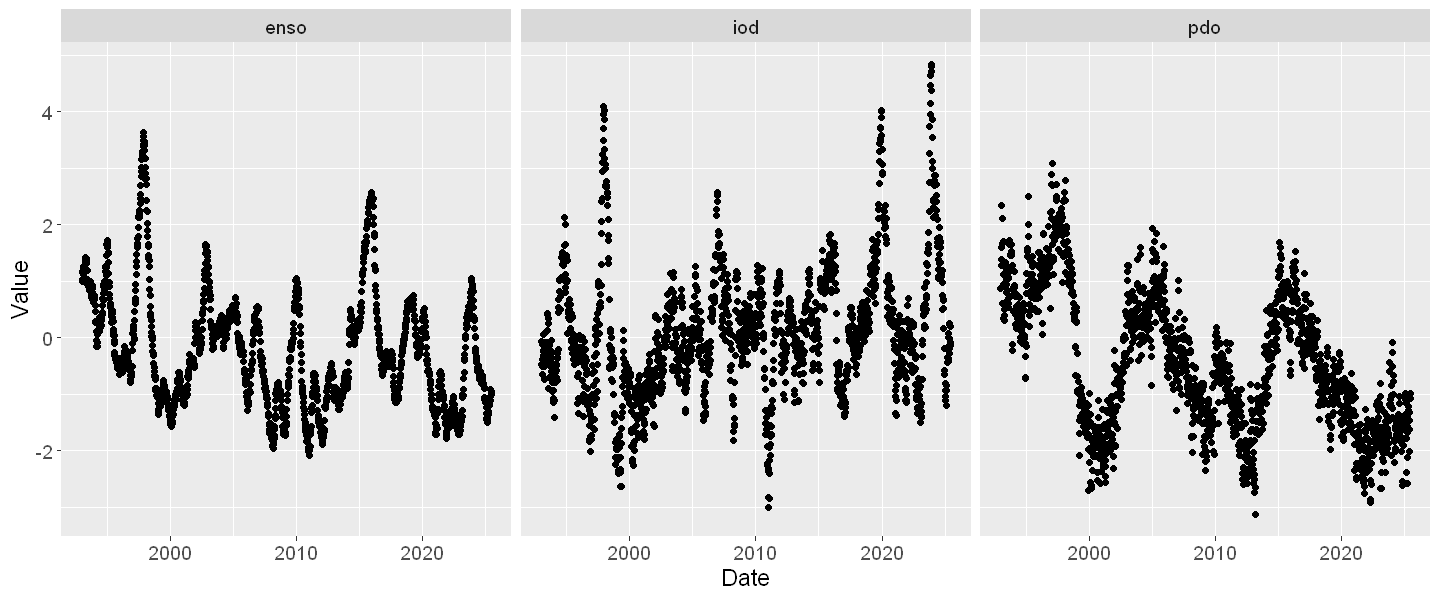

In [27]:
options(repr.plot.width = 12, repr.plot.height = 5)

sst_df %>% pivot_longer(-Date, names_to = "IndexName", values_to = "Value") %>%
    ggplot(aes(x = Date, y = Value)) + 
        geom_point() + 
        theme(text = element_text(size = 14)) + 
        facet_wrap(~IndexName)

In [28]:
interp_date_start = sst_df %>% pull(Date) %>% min
interp_date_end = sst_df %>% pull(Date) %>% max


#Date range to generate daily values for
to_interp_dates = seq(from = interp_date_start, to = interp_date_end, by = "day")

#Use linear interpolation to fill in gaps in the SST indices
enso_approx = approx(x = sst_df %>% pull(Date), y = sst_df %>% pull(enso), xout = to_interp_dates)
iod_approx = approx(x = sst_df %>% pull(Date), y = sst_df %>% pull(iod), xout = to_interp_dates)
pdo_approx = approx(x = sst_df %>% pull(Date), y = sst_df %>% pull(pdo), xout = to_interp_dates)

sst_filled_df = data.frame(Date = to_interp_dates, enso = enso_approx$y, iod = iod_approx$y, pdo = pdo_approx$y, num_days = 1) 

weekly_sst_df = sst_filled_df%>% left_join(week_cal, by = join_by(between(Date, WeekStart, WeekEnd))) %>% #Join to calendar
                    filter(!is.na(epiweek)) %>% select(-Date) %>% #Remove those with no epiweek (outside study period) and remove date column
                    group_by(epiweek, WeekStart, WeekMid, WeekEnd) %>% 
                    summarise(enso = mean(enso), iod = mean(iod), pdo = mean(pdo), num_days = sum(num_days)) %>% #Get average values
                    mutate(Year = str_sub(epiweek, 1, 4), Week = str_sub(epiweek, 5, 6)) %>% 
                    mutate(Year = as.integer(Year), Week = as.integer(Week)) #Split the Year and Week values


weekly_sst_df = weekly_sst_df %>% select(Year, Week, epiweek, WeekStart, WeekMid, WeekEnd, enso, iod, pdo, num_days)
weekly_sst_df

`summarise()` has grouped output by 'epiweek', 'WeekStart', 'WeekMid'. You can
override using the `.groups` argument.


Year,Week,epiweek,WeekStart,WeekMid,WeekEnd,enso,iod,pdo,num_days
<int>,<int>,<dbl>,<date>,<date>,<date>,<dbl>,<dbl>,<dbl>,<dbl>
2009,52,200952,2009-12-27,2009-12-31,2010-01-02,0.9990541,0.31898453,-0.17253788,7
2010,1,201001,2010-01-03,2010-01-07,2010-01-09,0.8927205,0.02054501,-0.25802370,7
2010,2,201002,2010-01-10,2010-01-14,2010-01-16,0.8464338,-0.06980604,-0.01756028,7
2010,3,201003,2010-01-17,2010-01-21,2010-01-23,0.8037493,0.03088384,-0.08674200,7
2010,4,201004,2010-01-24,2010-01-28,2010-01-30,0.8172340,0.23104214,0.13797844,7
2010,5,201005,2010-01-31,2010-02-04,2010-02-06,0.9589411,0.47496114,-0.05875791,7
2010,6,201006,2010-02-07,2010-02-11,2010-02-13,0.9477766,0.80929618,-0.42096556,7
2010,7,201007,2010-02-14,2010-02-18,2010-02-20,0.8648208,1.06691094,-0.37605966,7
2010,8,201008,2010-02-21,2010-02-25,2010-02-27,0.7998346,1.19119210,-0.12744194,7


# 7. Putting Things Together and Outputting Data

In [29]:
#Attach the COVID Stringency Index to the climate data to form the time-varying covariates dataframe
covid_index_attach = weekly_covid_state_df %>% select(uf, Year, Week, StringencyIndex)
time_varying_covs_df = state_clim_df %>% left_join(covid_index_attach, by = c("uf", "Year", "Week")) %>% 
                        replace_na(list(StringencyIndex = 0))

In [30]:
time_varying_covs_df

Date,epiweek,Year,Week,uf,uf_name,temp_min,temp_med,temp_max,precip_min,⋯,pressure_min,pressure_med,pressure_max,rel_humid_min,rel_humid_med,rel_humid_max,thermal_range,rainy_days,weight,StringencyIndex
<date>,<dbl>,<dbl>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2010-01-03,201001,2010,1,AC,Acre,23.60044,26.49356,30.43434,0.5354003,⋯,0.9674454,0.9704251,0.9725772,64.20072,81.66993,93.87733,6.833900,7.000000,1,0
2010-01-03,201001,2010,1,AL,Alagoas,23.02808,25.90269,29.60847,0.8536493,⋯,0.9786005,0.9802008,0.9814803,57.38410,76.18633,91.78871,6.580391,7.000000,1,0
2010-01-03,201001,2010,1,AM,Amazonas,23.99718,26.09028,29.06963,9.8894909,⋯,0.9851760,0.9877657,0.9897129,73.13621,87.02107,95.90969,5.072452,7.000000,1,0
2010-01-03,201001,2010,1,AP,Amapá,23.31326,25.09401,27.97362,9.6663464,⋯,0.9902269,0.9918292,0.9933572,76.45938,88.60799,96.03037,4.660359,7.000000,1,0
2010-01-03,201001,2010,1,BA,Bahia,22.41500,25.40299,29.39901,1.4390736,⋯,0.9625749,0.9643714,0.9658153,57.98651,76.44428,91.46335,6.984006,7.000000,1,0
2010-01-03,201001,2010,1,CE,Ceará,23.50226,26.26179,29.80374,1.8495285,⋯,0.9745918,0.9761705,0.9776382,57.43709,75.68233,90.27031,6.301482,6.982972,1,0
2010-01-03,201001,2010,1,DF,Distrito Federal,18.36569,22.19040,26.14364,2.4492000,⋯,0.8860714,0.8882429,0.8899429,61.94051,78.69350,93.45464,7.777957,7.000000,1,0
2010-01-03,201001,2010,1,ES,Espírito Santo,23.10227,26.25227,30.42470,0.1065720,⋯,0.9744901,0.9762097,0.9776309,56.36362,76.46684,90.85667,7.322432,6.974559,1,0
2010-01-03,201001,2010,1,GO,Goiás,20.06602,23.87315,27.80927,3.4032544,⋯,0.9117614,0.9140734,0.9158211,61.85675,78.38259,92.87529,7.743254,6.998511,1,0


In [31]:
main_cases_df = cases_df %>% rename(Cases = casos, Date = date) %>%
                    select(Date, epiweek, Year, Week, uf, uf_name, Cases, train_1, target_1, train_2, target_2, train_3, target_3)
main_cases_df

Date,epiweek,Year,Week,uf,uf_name,Cases,train_1,target_1,train_2,target_2,train_3,target_3
<date>,<dbl>,<int>,<int>,<chr>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>
2010-01-03,201001,2010,1,AC,Acre,760,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
2010-01-03,201001,2010,1,AL,Alagoas,73,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
2010-01-03,201001,2010,1,AM,Amazonas,155,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
2010-01-03,201001,2010,1,AP,Amapá,34,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
2010-01-03,201001,2010,1,BA,Bahia,539,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
2010-01-03,201001,2010,1,CE,Ceará,138,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
2010-01-03,201001,2010,1,DF,Distrito Federal,107,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
2010-01-03,201001,2010,1,ES,Espírito Santo,164,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
2010-01-03,201001,2010,1,GO,Goiás,5163,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE


In [32]:
calendar = week_cal %>% mutate(Year = str_sub(epiweek, 1, 4), Week = str_sub(epiweek, 5, 6)) %>% 
                        mutate(Year = as.integer(Year), Week = as.integer(Week))

set_info = main_cases_df %>% select(Year, Week, train_1, target_1, train_2, target_2, train_3, target_3) %>% distinct

calendar = calendar %>% left_join(set_info, by = c("Year", "Week")) %>% 
                        replace_na(list(train_1 = FALSE, target_1 = FALSE, train_2 = FALSE, target_2 = FALSE, train_3 = FALSE, target_3 = FALSE))
calendar

epiweek,WeekStart,WeekMid,WeekEnd,Year,Week,train_1,target_1,train_2,target_2,train_3,target_3
<dbl>,<date>,<date>,<date>,<int>,<int>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>
200952,2009-12-27,2009-12-31,2010-01-02,2009,52,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE
201001,2010-01-03,2010-01-07,2010-01-09,2010,1,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
201002,2010-01-10,2010-01-14,2010-01-16,2010,2,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
201003,2010-01-17,2010-01-21,2010-01-23,2010,3,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
201004,2010-01-24,2010-01-28,2010-01-30,2010,4,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
201005,2010-01-31,2010-02-04,2010-02-06,2010,5,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
201006,2010-02-07,2010-02-11,2010-02-13,2010,6,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
201007,2010-02-14,2010-02-18,2010-02-20,2010,7,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE
201008,2010-02-21,2010-02-25,2010-02-27,2010,8,TRUE,FALSE,TRUE,FALSE,TRUE,FALSE


In [33]:
# #Write values to csv files
main_cases_df %>% write.csv(file.path(output_dir, "DengueCases.csv"), row.names = FALSE) #CSV file with cases
time_varying_covs_df %>% write.csv(file.path(output_dir, "TimeVaryingCovs.csv"), row.names = FALSE) #CSV file with time-varying covariates (climate + COVID-19 stringency index)
merged_stats_df %>% write.csv(file.path(output_dir, "StaticCovs.csv"), row.names = FALSE) #CSV file with static covariate information - Koppen climate and Brazilian biomes
weekly_sst_df%>% write.csv(file.path(output_dir, "SSTIndices.csv"), row.names = FALSE) #CSV file containing interpolated - weekly aggregated SST indices
calendar %>% write.csv(file.path(output_dir, "Calendar.csv"), row.names = FALSE) #CSV file containing epiweek calendar information